# Statistical comparison of reinforcement-learning strategies

This notebook compares the **baseline, symmetry, disturbance, and reward-shaping strategies** together using one Friedman test.

## Statistical plan
- **Primary outcome:** mean survival steps at each pole length (higher is better).
- Pole length is the matched block: at each length, the test ranks the four strategies' mean survival scores.
- The Friedman test is an omnibus test. A significant result means at least one strategy differs, but does not identify which one.

The input CSVs contain one mean survival score per pole length, so results compare these trained models across the tested pole-length grid; they do not measure variation across independent training runs.

## 1. Imports and configuration

In [9]:
from pathlib import Path
import pandas as pd
from scipy import stats
from IPython.display import display

RESULTS_DIR = Path("results")

# Strategy label: path to summary CSV (one mean score per pole length).
STRATEGY_FILES = {
    "baseline": RESULTS_DIR / "baseline_summary.csv",
    "disturbance": RESULTS_DIR / "disturbance_summary.csv",
    "reward_shaping": RESULTS_DIR / "test_by_length_reward_shaping.csv",
    "symmetry": RESULTS_DIR / "symmetry_experiment_results.csv",
}

# Significance threshold used to interpret the omnibus p-value.
ALPHA = 0.05
PRIMARY_METRIC = "score"  # mean survival steps; higher is better


## 2. Load and standardize the data

In [10]:
def load_strategy(name, path):
    # Each input is already summarized to one mean survival score per length.
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"{name} summary CSV not found: {path}")
    df = pd.read_csv(path).copy()

    required = {"pole_length", "mean_score"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{name} summary CSV is missing columns: {sorted(missing)}")

    df["pole_length"] = pd.to_numeric(df["pole_length"], errors="coerce")
    df["mean_score"] = pd.to_numeric(df["mean_score"], errors="coerce")
    df = df.dropna(subset=["pole_length", "mean_score"])
    if df.empty:
        raise ValueError(f"{name} summary CSV has no valid pole-length scores")
    # Round all length grids consistently so matching rows can be paired.
    # CSVs may store the same grid as either exact linspace values or 2dp values.
    df["pole_length"] = df["pole_length"].round(2)
    if df["pole_length"].duplicated().any():
        raise ValueError(f"{name}: duplicate pole lengths after rounding to 2 decimals")
    df = df.rename(columns={"mean_score": "score"})
    df["strategy"] = name
    return df

loaded = {}
# Fail on missing or malformed inputs rather than silently omitting a strategy.
for name, path in STRATEGY_FILES.items():
    frame = load_strategy(name, path)
    loaded[name] = frame

if set(loaded) != set(STRATEGY_FILES):
    raise ValueError("All four strategy summary files must be loaded for the Friedman test.")
all_scores = pd.concat(loaded.values(), ignore_index=True)
print("Strategies loaded:", list(loaded))
# This overview reports the supplied per-length scores, not individual episodes.
display(pd.DataFrame([
    {"strategy": name,
     "pole_lengths": df["pole_length"].nunique(),
     "mean_score": df["score"].mean(),
     "sd_across_lengths": df["score"].std()}
    for name, df in loaded.items()
]).sort_values("strategy").reset_index(drop=True))


Strategies loaded: ['baseline', 'disturbance', 'reward_shaping', 'symmetry']


,strategy,pole_lengths,mean_score,sd_across_lengths
0,baseline,30,2399.823333,3521.727278
1,disturbance,30,5538.350000,4648.848034
2,reward_shaping,30,7908.926667,3140.190978
3,symmetry,30,644.143333,429.926977


## 3. Descriptive statistics and visualization

Scores are the supplied mean survival steps at each pole length. Overall averages are unweighted means across pole lengths; the Friedman test uses pole lengths shared by all four strategies.

,strategy,n_pole_lengths,mean_score,sd_across_lengths,median_score,min_score,max_score
0,baseline,30,2399.8233,3521.7273,482.75,140.0,13634.6
1,disturbance,30,5538.3500,4648.8480,4385.50,202.0,12370.0
2,reward_shaping,30,7908.9267,3140.1910,8578.65,506.7,11809.5
3,symmetry,30,644.1433,429.9270,475.65,196.7,2036.0


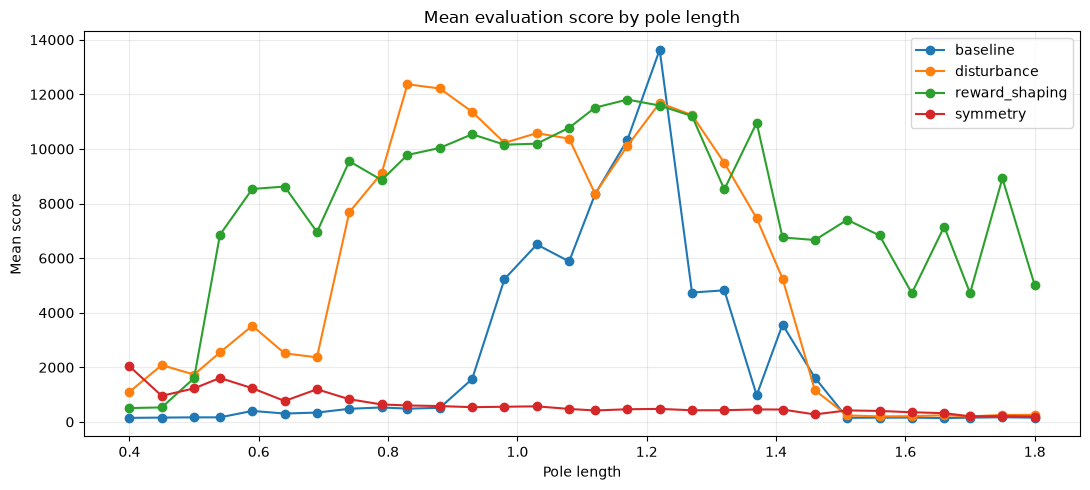

In [11]:
# Summarize how each strategy's per-length means vary over the tested grid.
summary_rows = []
for name, df in loaded.items():
    row = {
        "strategy": name,
        "n_pole_lengths": df["pole_length"].nunique(),
        "mean_score": df["score"].mean(),
        "sd_across_lengths": df["score"].std(),
        "median_score": df["score"].median(),
        "min_score": df["score"].min(),
        "max_score": df["score"].max(),
    }
    summary_rows.append(row)
descriptive = pd.DataFrame(summary_rows).sort_values("strategy")
display(descriptive.round(4))

# Plot the supplied mean survival score at each pole length for comparison.
length_means = all_scores.rename(columns={"score": "mean_score"})
try:
    import matplotlib.pyplot as plt
    plt.figure(figsize=(11, 5))
    for name, part in length_means.groupby("strategy"):
        plt.plot(part["pole_length"], part["mean_score"], marker="o", label=name)
    plt.xlabel("Pole length")
    plt.ylabel("Mean score")
    plt.title("Mean evaluation score by pole length")
    plt.legend()
    plt.grid(alpha=.25)
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Install matplotlib to display plots.")


## 4. Statistical tests across strategies

The Friedman test compares all four strategies together. Each shared pole length is one matched block, with one mean survival score from each strategy.

- A significant result indicates that at least one strategy differs; it does not identify which one.
- Kendall's W is included as an overall effect size (0 to 1).

This test evaluates the four trained models across the tested pole-length grid; the pole lengths are not independent training runs.

In [ ]:
# Keep only pole lengths present for all four strategies to make the test matched.
strategy_names = list(STRATEGY_FILES)
paired_scores = pd.concat(
    [loaded[name].set_index("pole_length")["score"].rename(name) for name in strategy_names],
    axis=1,
    join="inner",
).dropna()

if len(paired_scores) < 2:
    raise ValueError("The Friedman test needs at least two pole lengths shared by all four strategies.")

# Run one omnibus repeated-measures test over all four mean survival scores.
friedman = stats.friedmanchisquare(
    *(paired_scores[name].to_numpy() for name in strategy_names)
)
kendalls_w = friedman.statistic / (len(paired_scores) * (len(strategy_names) - 1))
friedman_results = pd.DataFrame([{
    "outcome": "mean survival steps",
    "n_strategies": len(strategy_names),
    "n_shared_pole_lengths": len(paired_scores),
    "friedman_statistic": friedman.statistic,
    "degrees_of_freedom": len(strategy_names) - 1,
    "p_value": friedman.pvalue,
    "kendalls_w": kendalls_w,
    "significant_at_0_05": friedman.pvalue < ALPHA,
}])
display(friedman_results.round(5))


## 5. Interpreting the result

A significant result supports an overall difference among the four strategies, but does not identify which strategy or strategies differ. No pairwise follow-up tests are included.

## 6. Export tables and write-up checklist

The CSV files contain the descriptive summaries and the single omnibus test. Report the test statistic, p-value, Kendall's W, number of shared pole lengths, and the limitation that pole lengths are not independent training runs.

In [ ]:
OUTPUT_DIR = Path("statistical_test_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

descriptive.to_csv(OUTPUT_DIR / "descriptive_statistics.csv", index=False)
friedman_results.to_csv(OUTPUT_DIR / "friedman_test_results.csv", index=False)

print(f"Saved tables to: {OUTPUT_DIR.resolve()}")